<a href="https://colab.research.google.com/github/Vimbyyy/Lettuce-analysis/blob/main/greenhouse_lettuce.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

**Do not forget to change runtime to GPU for faster execution of code**

In [ ]:
!pip install -q kaggle #Installs the official Kaggle library quietly in an environment so you can interact with Kaggle directly from code.

In [ ]:
import os #It imports Python's built-in `os` module, which allows your code to interact with your operating system
from getpass import getpass #It imports the `getpass` function from Python's built-in `getpass` module, which securely prompts you for sensitive input (like a password or token) without displaying the characters on the screen as you type.

os.environ["KAGGLE_API_TOKEN"] = getpass("Paste your Kaggle API token here: ") #Securely prompts you to paste your Kaggle API token, hides your input for privacy, and saves it as an environment variable so your code can authenticate with Kaggle.

Paste your Kaggle API token here: ··········


In [ ]:
!pip install -q -U kaggle #Tells pip to upgrade the Kaggle package to the latest available version, even if it is already installed on your system.


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 126.2/126.2 kB 4.7 MB/s eta 0:00:00


In [ ]:
!kaggle --version #Display your current kaggle version

Kaggle CLI 2.2.4


In [ ]:
!kaggle datasets list -s lettuce #Searches Kaggle for public datasets containing the word "lettuce" and displays the matching results.

ref                                                               title                                                  size  lastUpdated                 downloadCount  voteCount  usabilityRating  
----------------------------------------------------------------  -----------------------------------------------  ----------  --------------------------  -------------  ---------  ---------------  
jurijsruko/lettuce                                                Lettuce Growth Days Analysis                          63501  2024-10-15 17:17:39.837000          65354        323                1  
baronn/lettuce-npk-dataset                                        Lettuce NPK dataset                               353828161  2023-02-01 13:11:29.403000           3068         33             0.75  
ashishjstar/lettuce-diseases                                      Lettuce Diseases                                 1347534346  2024-04-11 19:37:31.840000           2693         27            0.875  
every

In [ ]:
!mkdir -p /content/lettuce_dataset #Creates a new folder named lettuce_dataset at /content to store your files.

!kaggle datasets download \
    -d ashimstha/lettuce-health-compiled-dataset \
    -p /content/lettuce_dataset  #Downloads the specified lettuce health dataset directly from Kaggle and saves it into your /content/lettuce_dataset folder.

Dataset URL: https://www.kaggle.com/datasets/ashimstha/lettuce-health-compiled-dataset
License(s): MIT
100% 382M/382M [00:07<00:00, 53.4MB/s]



In [ ]:
!ls -lh /content/lettuce_dataset #Lists all files inside the /content/lettuce_dataset folder, showing their detailed info and human-readable sizes

total 383M
-rw-r--r-- 1 root root 383M Sep 11  2025 lettuce-health-compiled-dataset.zip


In [ ]:
import zipfile #Imports Python's built-in zipfile module so your code can extract compressed .zip files.
import os

dataset_dir = "/content/lettuce_dataset" #Creates a variable named dataset_dir to store the path of your dataset folder so you can easily reference it later in your code.

zip_files = [f for f in os.listdir(dataset_dir) if f.endswith(".zip")] #Scans your dataset directory and creates a list containing only the names of the .zip files found inside it.

print("ZIP file:", zip_files)


#Opens the downloaded zip file and extracts all its contents into your dataset directory.
with zipfile.ZipFile(os.path.join(dataset_dir, zip_files[0]), "r") as zip_ref:
    zip_ref.extractall(dataset_dir)

print("Extraction complete!")

ZIP file: ['lettuce-health-compiled-dataset.zip']
Extraction complete!


1. **Dataset Loading and** **Preparation**

In [ ]:
# Import the libraries required for analysing and visualising the dataset
import os
import pandas as pd #The standard, powerful Python library used for data manipulation, analysis, and working with tabular data (like spreadsheets, CSVs, and dataframes
import matplotlib.pyplot as plt #A popular plotting module within the Matplotlib library used to create 2D graphs, charts, and data visualizations
from PIL import Image #Imports the Pillow library (the modern, updated version of the Python Imaging Library), which is used for opening, editing, and saving image files.
from collections import Counter #Imports the Counter class from Python's standard library to easily count and tally items (like counting the number of images per category in a dataset).

# Define the path to the extracted lettuce dataset
dataset_path = "/content/lettuce_dataset/plant-health"

# Define the paths for the two classes in the dataset
healthy_path = os.path.join(dataset_path, "healthy")
unhealthy_path = os.path.join(dataset_path, "unhealthy")

# Display the dataset paths to confirm that the correct folders have been located
print("Dataset loaded successfully.")
print("Healthy folder:", healthy_path)
print("Unhealthy folder:", unhealthy_path)

Dataset loaded successfully.
Healthy folder: /content/lettuce_dataset/plant-health/healthy
Unhealthy folder: /content/lettuce_dataset/plant-health/unhealthy


**2. Dataset Class** **Distribution**

The dataset contains two classes: healthy and unhealthy lettuce.
The number of images in each class is counted to understand the distribution of the dataset and determine whether there is any significant class imbalance.

In [ ]:
# Get the list of image files in each class folder
healthy_images = [
    file for file in os.listdir(healthy_path)
    if file.lower().endswith((".jpg", ".jpeg", ".png"))
]

unhealthy_images = [
    file for file in os.listdir(unhealthy_path)
    if file.lower().endswith((".jpg", ".jpeg", ".png"))
]

# Count the number of images in each class
healthy_count = len(healthy_images)
unhealthy_count = len(unhealthy_images)

# Calculate the total number of images
total_images = healthy_count + unhealthy_count

# Calculate the percentage of each class
healthy_percentage = (healthy_count / total_images) * 100
unhealthy_percentage = (unhealthy_count / total_images) * 100

# Display the results
print("Dataset Class Distribution:")
print(f"Healthy images: {healthy_count}")
print(f"Unhealthy images: {unhealthy_count}")
print(f"Total images: {total_images}")
print(f"Healthy percentage: {healthy_percentage:.2f}%")
print(f"Unhealthy percentage: {unhealthy_percentage:.2f}%")

Dataset Class Distribution:
Healthy images: 326
Unhealthy images: 381
Total images: 707
Healthy percentage: 46.11%
Unhealthy percentage: 53.89%


**3. Visualisation of Class Distribution**

A bar chart is used to visually compare the number of healthy and unhealthy lettuce images in the dataset.

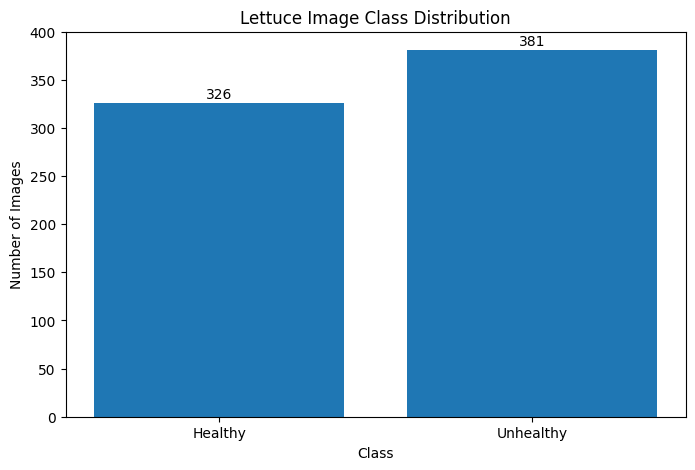

In [ ]:
# Create labels and corresponding image counts
classes = ["Healthy", "Unhealthy"]
counts = [healthy_count, unhealthy_count]

# Create a bar chart
plt.figure(figsize=(8, 5))
plt.bar(classes, counts)

# Add chart title and axis labels
plt.title("Lettuce Image Class Distribution")
plt.xlabel("Class")
plt.ylabel("Number of Images")

# Display the exact number above each bar
for i, count in enumerate(counts):
    plt.text(i, count + 5, str(count), ha="center")

# Display the chart
plt.show()

**Interpretation**

The dataset contains 707 lettuce images, with 326 images classified as healthy and 381 classified as unhealthy. The healthy class represents approximately 46.11% of the dataset, while the unhealthy class represents approximately 53.89%.

Although the unhealthy class contains slightly more images, the difference between the two classes is relatively small. Therefore, the dataset does not show a severe class imbalance and is suitable for binary image classification.

###**5. Image Properties**

The image properties are analysed to determine the dimensions, file formats, colour modes, and readability of the images. This information helps assess the quality and consistency of the dataset before applying it to a deep learning model.

In [ ]:
# Create a list containing all image files from both classes
all_images = []

for class_name, folder_path in [
    ("Healthy", healthy_path),
    ("Unhealthy", unhealthy_path)
]:
    for filename in os.listdir(folder_path):
        # Only include common image file formats
        if filename.lower().endswith((".jpg", ".jpeg", ".png")):
            all_images.append(
                (class_name, os.path.join(folder_path, filename))
            )

# Display the total number of image files found
print("Total image files analysed:", len(all_images))

Total image files analysed: 707


###**5.1 Image Dimensions**

The dimensions of the images are examined to determine whether the dataset contains images of consistent or varying sizes.

In [ ]:
# Create a list to store the dimensions of all images
image_dimensions = []

# Check the dimensions of each image
for class_name, filepath in all_images:
    try:
        with Image.open(filepath) as img:
            image_dimensions.append(img.size)
    except Exception as e:
        print("Could not read:", filepath)

# Count how frequently each dimension occurs
dimension_counts = Counter(image_dimensions)

# Display the most common image dimensions
print("Most common image dimensions:")
for dimension, count in dimension_counts.most_common(10):
    print(f"{dimension}: {count} images")

Most common image dimensions:
(1024, 1024): 85 images
(1023, 1006): 40 images
(225, 225): 25 images
(1023, 1005): 23 images
(1024, 1003): 20 images
(474, 355): 15 images
(1024, 1007): 8 images
(1500, 1000): 7 images
(1000, 1000): 7 images
(640, 480): 6 images


###**5.2 Image File Formats**

The file formats of the images are analysed to determine which formats are present in the dataset.

In [ ]:
# Create a counter to store the image file formats
image_formats = Counter()

# Check the format of every image
for class_name, filepath in all_images:
    try:
        with Image.open(filepath) as img:
            image_formats[img.format] += 1
    except Exception as e:
        print("Could not read:", filepath)

# Display the distribution of image formats
print("Image format distribution:")

for image_format, count in image_formats.items():
    print(f"{image_format}: {count} images")

Image format distribution:
JPEG: 436 images
PNG: 271 images


### **5.3 Image Colour Modes**

The colour mode of the images is examined to determine whether the images are RGB, grayscale, or another format. Colour information can be important for identifying visual differences between healthy and unhealthy lettuce.

In [ ]:
# Create a counter to store the colour modes
colour_modes = Counter()

# Check the colour mode of every image
for class_name, filepath in all_images:
    try:
        with Image.open(filepath) as img:
            colour_modes[img.mode] += 1
    except Exception as e:
        print("Could not read:", filepath)

# Display the colour mode distribution
print("Colour mode distribution:")

for mode, count in colour_modes.items():
    print(f"{mode}: {count} images")

Colour mode distribution:
RGB: 697 images
RGBA: 10 images


### 5.4 **Image Readability Check**

Each image is opened to identify any files that may be corrupted or unreadable. Identifying such files is important before using the dataset for model development.

In [ ]:
# Keep track of images that cannot be opened
unreadable_images = []

# Attempt to open every image in the dataset
for class_name, filepath in all_images:
    try:
        with Image.open(filepath) as img:
            img.verify()
    except Exception:
        unreadable_images.append(filepath)

# Display the result
print("Total unreadable images:", len(unreadable_images))

if len(unreadable_images) == 0:
    print("All images are readable.")
else:
    print("Unreadable image files:")
    for filepath in unreadable_images:
        print(filepath)

Total unreadable images: 0
All images are readable.


## **6. Visualisation of Sample Images**

Sample images from the healthy and unhealthy classes are displayed to visually inspect the dataset. This helps identify differences in plant appearance and observe variations in image quality, background, lighting, and colour.

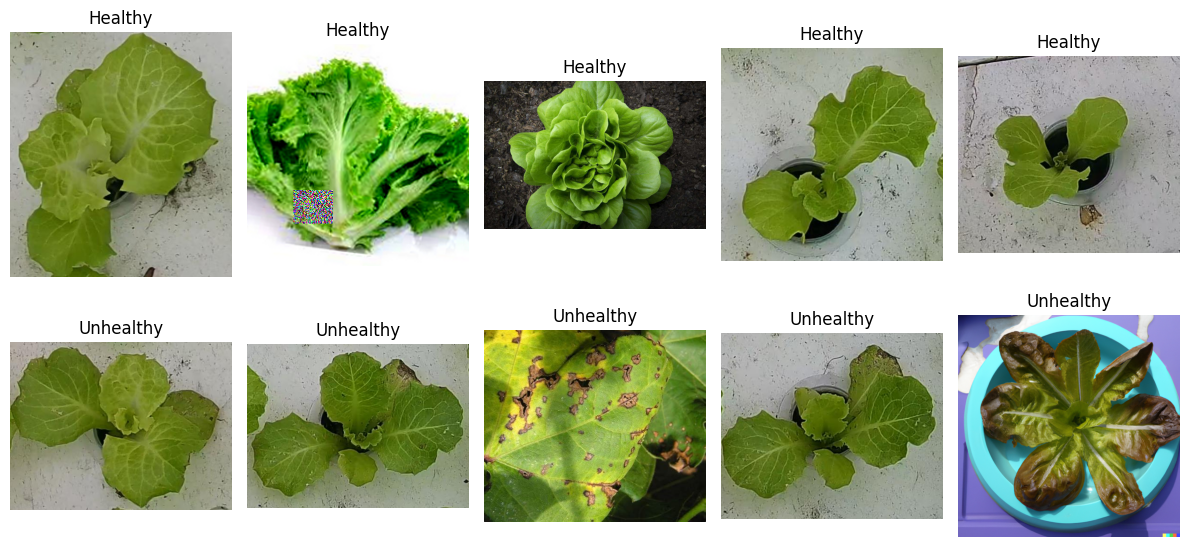

In [ ]:
# Set the number of sample images to display from each class
num_samples = 5

# Create a figure to display healthy and unhealthy samples
plt.figure(figsize=(12, 6))

# Display sample healthy images
for i, filename in enumerate(healthy_images[:num_samples]):
    image_path = os.path.join(healthy_path, filename)

    # Open the image
    image = Image.open(image_path)

    # Add the image to the first row
    plt.subplot(2, num_samples, i + 1)
    plt.imshow(image)
    plt.title("Healthy")
    plt.axis("off")

# Display sample unhealthy images
for i, filename in enumerate(unhealthy_images[:num_samples]):
    image_path = os.path.join(unhealthy_path, filename)

    # Open the image
    image = Image.open(image_path)

    # Add the image to the second row
    plt.subplot(2, num_samples, i + num_samples + 1)
    plt.imshow(image)
    plt.title("Unhealthy")
    plt.axis("off")

# Adjust spacing between images
plt.tight_layout()

# Display the figure
plt.show()

## **7. Analysis of Dataset Characteristics**

The dataset contains 707 lettuce images, consisting of 326 healthy images (46.11%) and 381 unhealthy images (53.89%). The relatively small difference between the two classes indicates that the dataset is reasonably balanced, although the unhealthy class contains slightly more images.

The images have varying dimensions, with the most common size being 1024 × 1024 pixels, occurring in 85 images. Other dimensions include 1023 × 1006, 225 × 225, and 1023 × 1005 pixels. The variation in image dimensions indicates that image resizing will be necessary during preprocessing before the dataset can be used as input to a CNN.

Two image formats are present: JPEG (436 images) and PNG (271 images). Most images are RGB (697 images), while 10 images use RGBA colour mode. This indicates that the majority of the dataset contains standard three-channel colour images, which are appropriate for colour-based image classification.

All 707 images were successfully opened and verified, with no unreadable images detected. This suggests that the dataset does not contain obvious corrupted image files that would need to be removed before further analysis.

## **8. Dataset Suitability for the Proposed Project**

The dataset is suitable for the proposed deep learning-based lettuce health classification system because it contains labelled images representing two lettuce health conditions: healthy and unhealthy. The relatively balanced class distribution provides a suitable foundation for binary image classification.

The presence of colour images is also useful because visual characteristics such as leaf colour and appearance may provide information for distinguishing between healthy and unhealthy plants. However, the variation in image dimensions and the presence of both JPEG and PNG formats indicate that preprocessing will be required before training a CNN.

Overall, the dataset provides an appropriate starting point for developing the image-based monitoring component of the proposed smart automated greenhouse system.

## **9. Conclusion**

Descriptive analytics were performed on the selected Kaggle lettuce health image dataset using Google Colab. The dataset contains 707 images, with 326 healthy and 381 unhealthy images. The dataset was found to contain JPEG and PNG images, primarily using RGB colour mode, with varying image dimensions. All images were successfully verified as readable.

The analysis indicates that the dataset is appropriate for the proposed binary lettuce health classification task. The findings will inform the preprocessing stage and subsequent development of a CNN-based deep learning model for lettuce health monitoring.

In [ ]:
import tensorflow as tf  # Import TensorFlow, a deep learning library used to build and train our CNN model
import matplotlib.pyplot as plt  # Import Matplotlib for data visualization
import numpy as np # Import NumPy, a library used for numerical calculations and working with arrays
import os # Import the OS module to interact with files and folders on the computer

print("TensorFlow version:", tf.__version__)

TensorFlow version: 2.21.0


In [ ]:
!ls /content/lettuce_dataset

lettuce-health-compiled-dataset.zip  plant-health


In [ ]:
import os

dataset_path = "/content/lettuce_dataset"

print(os.listdir(dataset_path))

['plant-health', 'lettuce-health-compiled-dataset.zip']


In [ ]:
plant_path = "/content/lettuce_dataset/plant-health"

print(os.listdir(plant_path))

['healthy', 'unhealthy']


In [ ]:
import tensorflow as tf  # Import TensorFlow for loading and processing our image dataset

dataset_path = "/content/lettuce_dataset/plant-health"  # Path to the Healthy and Unhealthy folders

# Load 70% of the images as training data
train_dataset = tf.keras.utils.image_dataset_from_directory(
    dataset_path,                  # Load images from our dataset folder
    validation_split=0.30,         # Reserve 30% of the images
    subset="training",             # Use the remaining 70% for training
    seed=42,                       # Keep the split consistent every time we run the code
    image_size=(224, 224),         # Resize every image to 224 × 224 pixels
    batch_size=None,               # Do not create batches yet; split individual images first
    shuffle=True                   # Shuffle the images before splitting
)

# Load the remaining 30% of the images
remaining_dataset = tf.keras.utils.image_dataset_from_directory(
    dataset_path,                  # Load images from our dataset folder
    validation_split=0.30,         # Reserve the same 30% of the images
    subset="validation",           # Get the remaining 30%
    seed=42,                       # Use the same seed so the split matches the training data
    image_size=(224, 224),         # Resize every image to 224 × 224 pixels
    batch_size=None,               # Keep individual images instead of creating batches
    shuffle=True                   # Shuffle the remaining images
)

# Count how many individual images are in the remaining 30%
remaining_count = tf.data.experimental.cardinality(remaining_dataset).numpy()  # Find the number of images

# Calculate half of the remaining images for validation
validation_count = remaining_count // 2  # Divide the remaining images into two approximately equal groups

# Create the validation dataset using the first half
validation_dataset = remaining_dataset.take(validation_count)  # Take the first half for validation

# Create the test dataset using the second half
test_dataset = remaining_dataset.skip(validation_count)  # Use the remaining images for testing

# Now create batches of 32 images for each dataset
train_dataset = train_dataset.batch(32)  # Group training images into batches of 32
validation_dataset = validation_dataset.batch(32)  # Group validation images into batches of 32
test_dataset = test_dataset.batch(32)  # Group test images into batches of 32

# Display the number of batches in each dataset
print("Training batches:", tf.data.experimental.cardinality(train_dataset).numpy())
print("Validation batches:", tf.data.experimental.cardinality(validation_dataset).numpy())
print("Test batches:", tf.data.experimental.cardinality(test_dataset).numpy())

Found 707 files belonging to 2 classes.
Using 495 files for training.
Found 707 files belonging to 2 classes.
Using 212 files for validation.
Training batches: 16
Validation batches: 4
Test batches: 4


In [ ]:
# DEEP LEARNING PIPELINE - STEP 6
# VIEW IMAGES FROM A TRAINING BATCH


class_names = ["Healthy", "Unhealthy"]  # Names of our two classes

for images, labels in train_dataset.take(1):
    print("Batch shape:", images.shape)  # Show the shape of the image batch
    print("Labels:", labels.numpy())     # Display the class labels

Batch shape: (32, 224, 224, 3)
Labels: [0 0 1 1 1 0 1 1 1 0 1 1 1 0 1 1 0 1 1 0 1 0 1 0 1 0 1 0 1 0 1 0]


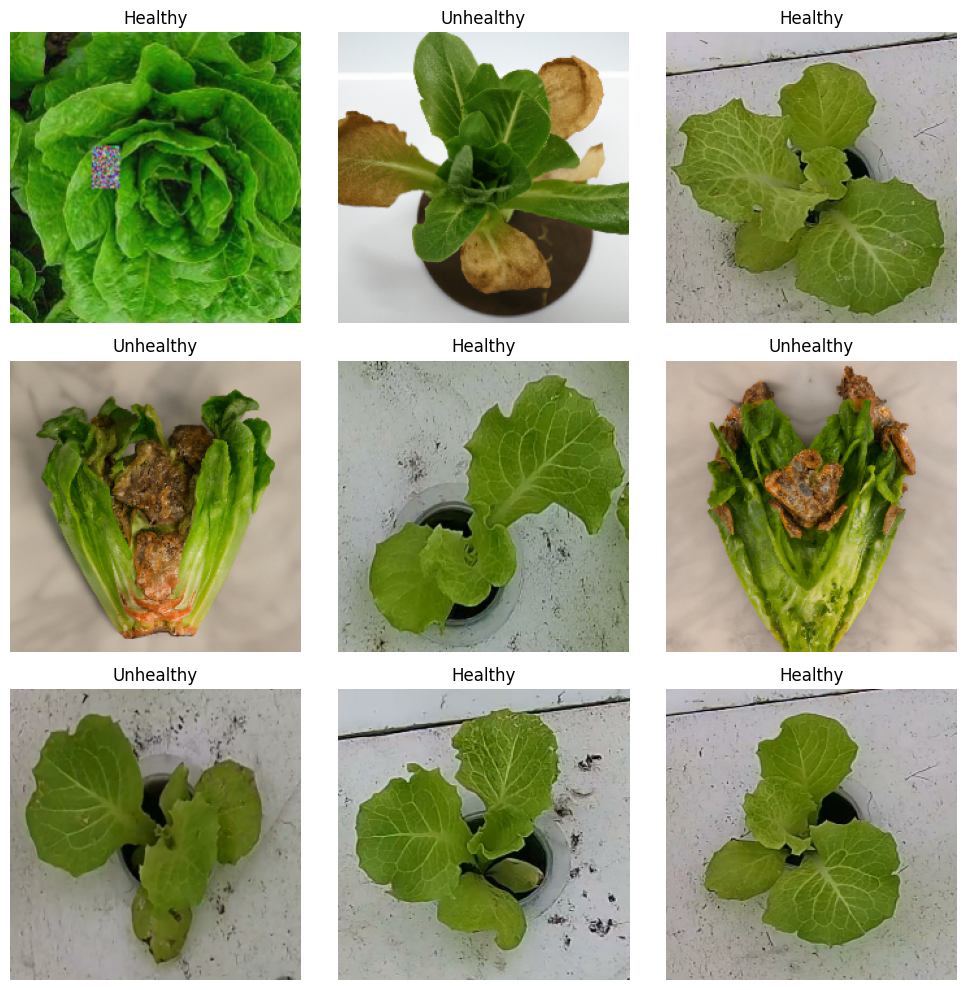

In [ ]:
import matplotlib.pyplot as plt  # Import Matplotlib to display our images

for images, labels in train_dataset.take(1):  # Take one batch of training images
    plt.figure(figsize=(10, 10))  # Create a figure for displaying the images

    for i in range(9):  # Display the first 9 images in the batch
        ax = plt.subplot(3, 3, i + 1)  # Create a 3 × 3 grid
        plt.imshow(images[i].numpy().astype("uint8"))  # Display the image
        plt.title(class_names[labels[i]])  # Show whether the image is Healthy or Unhealthy
        plt.axis("off")  # Hide the axis numbers

    plt.tight_layout()  # Adjust spacing between the images
    plt.show()  # Display the figure

In [ ]:
# DEEP LEARNING PIPELINE - STEP 7
# DATA AUGMENTATION AND NORMALIZATION

from tensorflow.keras import layers #Imports TensorFlow's Keras layers module so you can easily build neural network architectures

# Data augmentation: create slightly different versions
# of training images to help the model generalize better
data_augmentation = tf.keras.Sequential([
    layers.RandomFlip("horizontal"),       # Randomly flip images horizontally
    layers.RandomRotation(0.2),            # Randomly rotate images
    layers.RandomZoom(0.2),                # Randomly zoom in or out
])

# Normalize pixel values from 0-255 to 0-1
normalization = layers.Rescaling(1./255)

# Apply augmentation and normalization to training images
train_dataset = train_dataset.map(
    lambda x, y: (normalization(data_augmentation(x)), y)
)

# Normalize validation images only
# We do not augment validation images because they should
# represent the original data used to evaluate the model
validation_dataset = validation_dataset.map(
    lambda x, y: (normalization(x), y)
)

print("Data augmentation and normalization completed.")

Data augmentation and normalization completed.


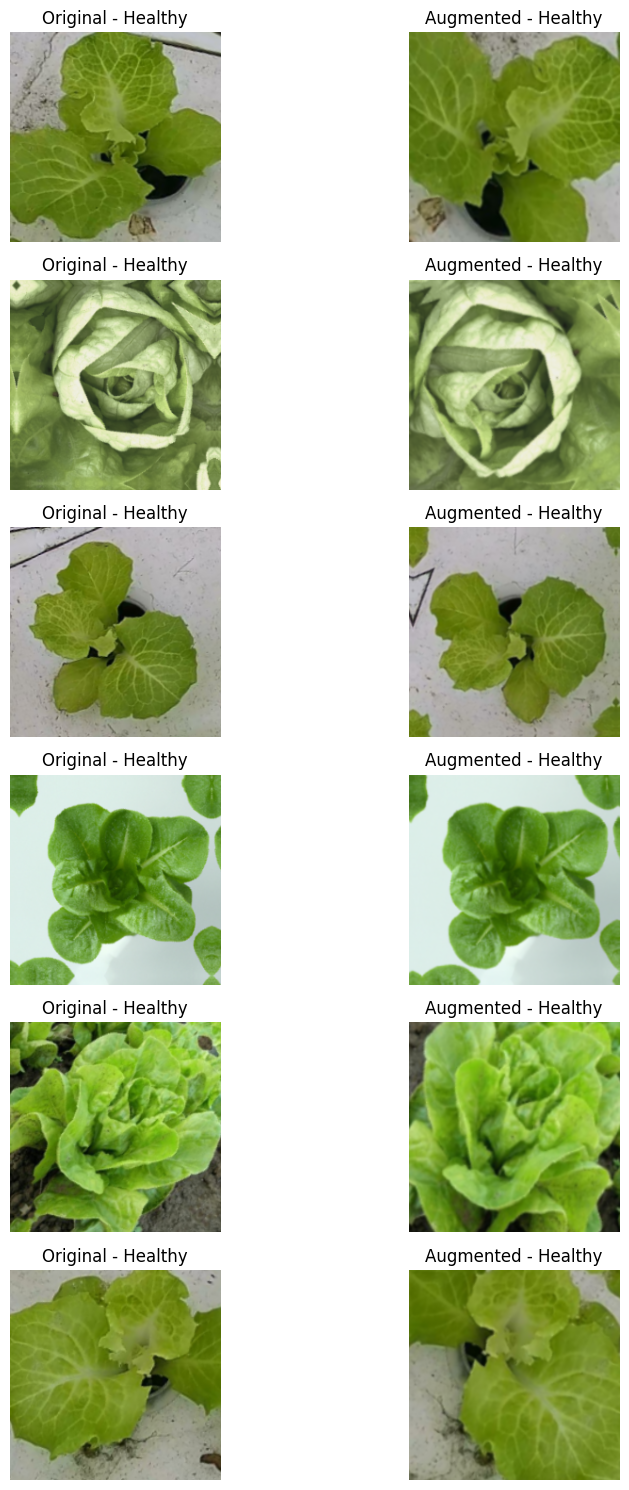

In [ ]:
# DISPLAY ORIGINAL VS AUGMENTED IMAGES

import matplotlib.pyplot as plt

# Get one batch of images
for images, labels in train_dataset.take(1):

    plt.figure(figsize=(10, 15))

    for i in range(6):

        # Original image
        plt.subplot(6, 2, 2 * i + 1)
        plt.imshow(images[i])
        plt.title("Original - " + class_names[labels[i]])
        plt.axis("off")

        # Augmented image
        augmented_image = data_augmentation(
            images[i:i+1],
            training=True
        )

        plt.subplot(6, 2, 2 * i + 2)
        plt.imshow(augmented_image[0])
        plt.title("Augmented - " + class_names[labels[i]])
        plt.axis("off")

    plt.tight_layout()
    plt.show()

In [ ]:
# STEP 8: BUILD THE CNN MODEL

import tensorflow as tf
from tensorflow.keras import layers, models

# Create the CNN model
model = models.Sequential([

    # Input layer
    layers.Input(shape=(224, 224, 3)),

    # First convolution block
    layers.Conv2D(32, (3, 3), activation='relu'),
    layers.MaxPooling2D((2, 2)),

    # Second convolution block
    layers.Conv2D(64, (3, 3), activation='relu'),
    layers.MaxPooling2D((2, 2)),

    # Third convolution block
    layers.Conv2D(128, (3, 3), activation='relu'),
    layers.MaxPooling2D((2, 2)),

    # Convert feature maps into a single vector
    layers.Flatten(),

    # Fully connected layer
    layers.Dense(128, activation='relu'),

    # Prevent overfitting
    layers.Dropout(0.5),

    # Output layer
    # 1 neuron because we have two classes:
    # Healthy and Unhealthy
    layers.Dense(1, activation='sigmoid')
])

# Display the model architecture
model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 222, 222, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 111, 111, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 109, 109, 64)   │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 54, 54, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 52, 52, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 26, 26, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 86528)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │    11,075,712 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │           129 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 11,169,089 (42.61 MB)

 Trainable params: 11,169,089 (42.61 MB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
# STEP 9: COMPILE THE CNN MODEL

model.compile( #Configures your neural network model for training by bringing together the optimizer, loss function, and evaluation metrics.
    optimizer='adam', #Sets the optimization algorithm to Adam (Adaptive Moment Estimation), a popular and efficient optimizer that automatically adjusts learning rates during training.
    loss='binary_crossentropy', #The loss function used to measure how wrong the model's predictions are
    metrics=['accuracy'] #Tells the model to track and evaluate performance during training by measuring the percentage of correct predictions.
)

print("CNN model compiled successfully!")

CNN model compiled successfully!


In [ ]:
# STEP 10: TRAIN THE CNN MODEL

# Train the CNN using the training dataset
history = model.fit( #Trains your neural network model and saves the training and validation history (loss and accuracy scores recorded at each step) into a variable called history.
    train_dataset, #The dataset containing your training images and labels that the model learns from.
    validation_data=validation_dataset, #A separate dataset used at the end of every epoch to evaluate how well your model generalizes to unseen validation images.
    epochs=75 #Specifies that the model will train by passing through the entire training dataset 10 complete times.
)

print("Training completed!")

Epoch 1/75
16/16 ━━━━━━━━━━━━━━━━━━━━ 28s 1s/step - accuracy: 0.5172 - loss: 0.8646 - val_accuracy: 0.6321 - val_loss: 0.6790
Epoch 2/75
16/16 ━━━━━━━━━━━━━━━━━━━━ 9s 576ms/step - accuracy: 0.5879 - loss: 0.6684 - val_accuracy: 0.4434 - val_loss: 0.7826
Epoch 3/75
16/16 ━━━━━━━━━━━━━━━━━━━━ 10s 585ms/step - accuracy: 0.6444 - loss: 0.6101 - val_accuracy: 0.7642 - val_loss: 0.4927
Epoch 4/75
16/16 ━━━━━━━━━━━━━━━━━━━━ 9s 568ms/step - accuracy: 0.7333 - loss: 0.5418 - val_accuracy: 0.7075 - val_loss: 0.5272
Epoch 5/75
16/16 ━━━━━━━━━━━━━━━━━━━━ 9s 575ms/step - accuracy: 0.7636 - loss: 0.4875 - val_accuracy: 0.6698 - val_loss: 0.5419
Epoch 6/75
16/16 ━━━━━━━━━━━━━━━━━━━━ 10s 589ms/step - accuracy: 0.7434 - loss: 0.4978 - val_accuracy: 0.7453 - val_loss: 0.4566
Epoch 7/75
16/16 ━━━━━━━━━━━━━━━━━━━━ 9s 562ms/step - accuracy: 0.7313 - loss: 0.5287 - val_accuracy: 0.6321 - val_loss: 0.5183
Epoch 8/75
16/16 ━━━━━━━━━━━━━━━━━━━━ 9s 553ms/step - accuracy: 0.7677 - loss: 0.4810 - val_accuracy: 0.